# CSE301 Machine Learning Capstone — Classification Algorithms 9 & 10
## Review 2 | HeartFailureDataset.csv

**Algorithm 9:** Bagging Classifier (Decision Tree base estimator)  
**Algorithm 10:** MLP Classifier (Neural Network)

Both models use the same train/test split and preprocessing so their results can be compared fairly.

**Target:** `cardio` (binary classification). The target is not included in the input features. The notebook includes missing-value handling, duplicate checks, feature engineering, outlier checks and boxplots, scaling, training, tuning, and the required classification metrics.

**Run tip:** Keep `HeartFailureDataset.csv` in the same folder as this notebook. Run all cells from the top in order. The tuning cells use a sample to finish faster.

## 1. Imports and configuration

In [1]:
# If needed, install dependencies:
# %pip install pandas numpy matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
    classification_report, RocCurveDisplay
)

RANDOM_STATE = 42
DATA_PATH = "HeartFailureDataset.csv"
TARGET_COLUMN = "cardio"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load and audit the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df[TARGET_COLUMN].value_counts(dropna=False).rename_axis("class").to_frame("count"))

Dataset shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62,110,80,1,1,0,0,1,0
1,1,20228,1,156,85,140,90,3,1,0,0,1,1
2,2,18857,1,165,64,130,70,3,1,0,0,0,1
3,3,17623,2,169,82,150,100,1,1,0,0,1,1
4,4,17474,1,156,56,100,60,1,1,0,0,0,0



Data types:


,dtype
id,int64
age,int64
gender,int64
height,int64
weight,int64
ap_hi,int64
ap_lo,int64
cholesterol,int64
gluc,int64
smoke,int64



Missing values:


,missing_count
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0



Duplicate rows: 0

Target distribution:


,count
class,
0,35021
1,34979


## 3. Cleaning and feature engineering

In [3]:
data = df.copy().drop_duplicates().reset_index(drop=True)

# Convert age from days to years
if "age" in data.columns:
    data["age_years"] = data["age"] / 365.25
    data = data.drop(columns=["age"])

# Create BMI from height (cm) and weight (kg)
if {"height", "weight"}.issubset(data.columns):
    data["bmi"] = data["weight"] / ((data["height"] / 100) ** 2)
    data = data.drop(columns=["height", "weight"])

if TARGET_COLUMN not in data.columns:
    raise ValueError(f"Target '{TARGET_COLUMN}' not found. Available columns: {data.columns.tolist()}")

y = data[TARGET_COLUMN].copy()
drop_cols = [c for c in ["id", TARGET_COLUMN] if c in data.columns]
X = data.drop(columns=drop_cols).copy()

print("Target classes:", sorted(y.dropna().unique().tolist()))
print("Predictor columns:", X.columns.tolist())
print("Predictor shape:", X.shape)

Target classes: [0, 1]
Predictor columns: ['gender', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'bmi']
Predictor shape: (70000, 10)


## 4. Exploratory data analysis

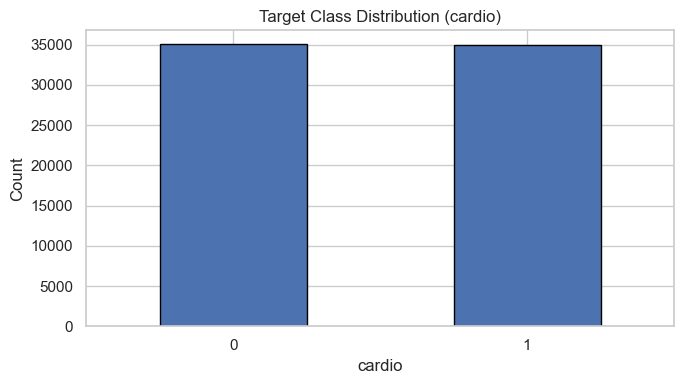

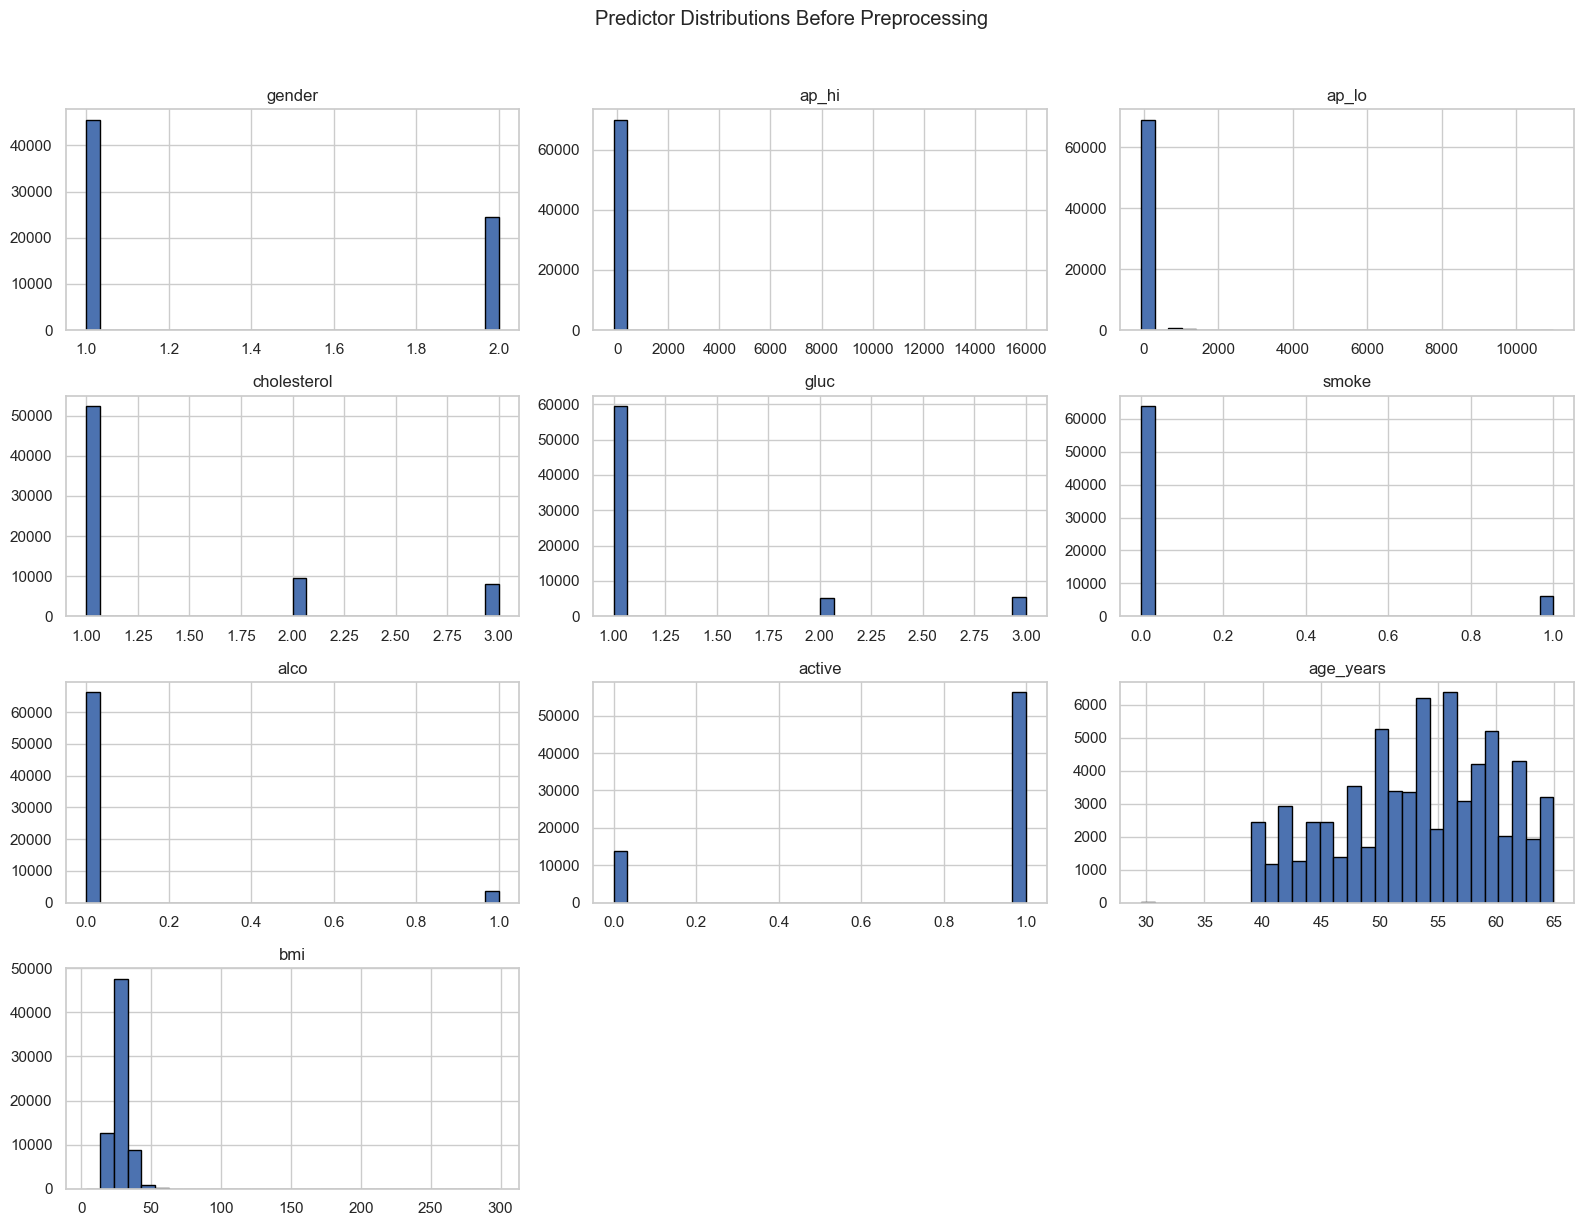

In [4]:
plt.figure(figsize=(7, 4))
y.value_counts().sort_index().plot(kind="bar", edgecolor="black")
plt.title("Target Class Distribution (cardio)")
plt.xlabel("cardio")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

X.hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Predictor Distributions Before Preprocessing", y=1.02)
plt.tight_layout()
plt.show()

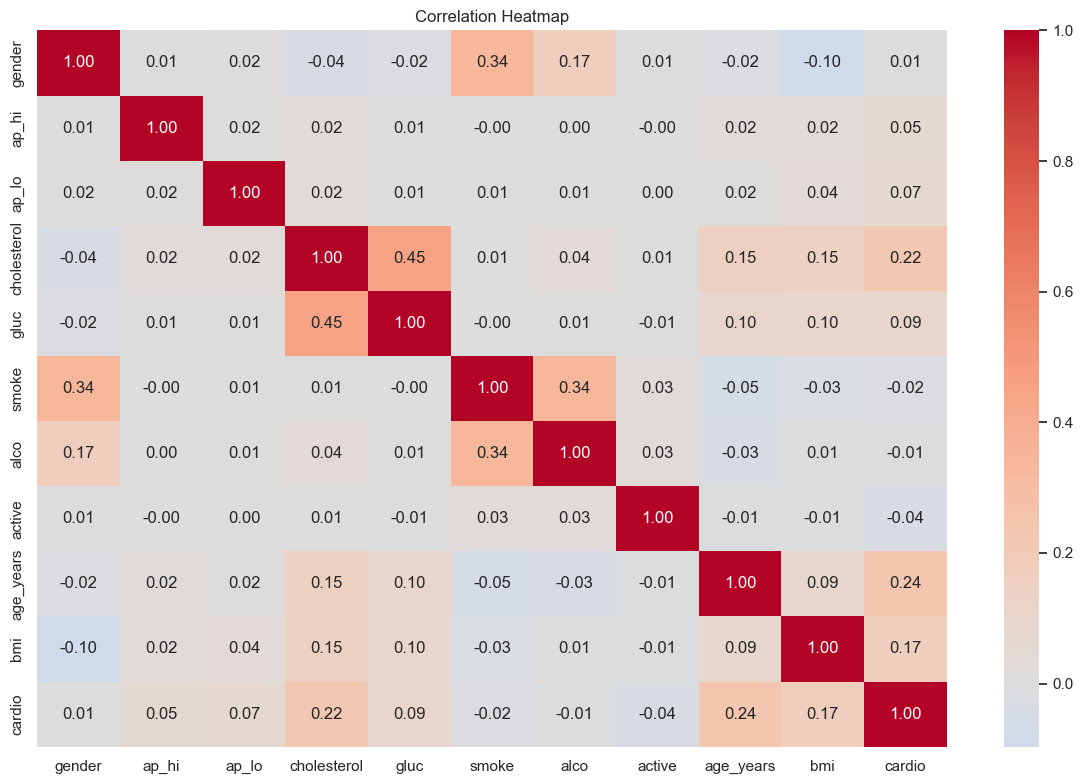

In [5]:
eda = pd.concat([X.select_dtypes(include=np.number), y.rename(TARGET_COLUMN)], axis=1)
plt.figure(figsize=(12, 8))
sns.heatmap(eda.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

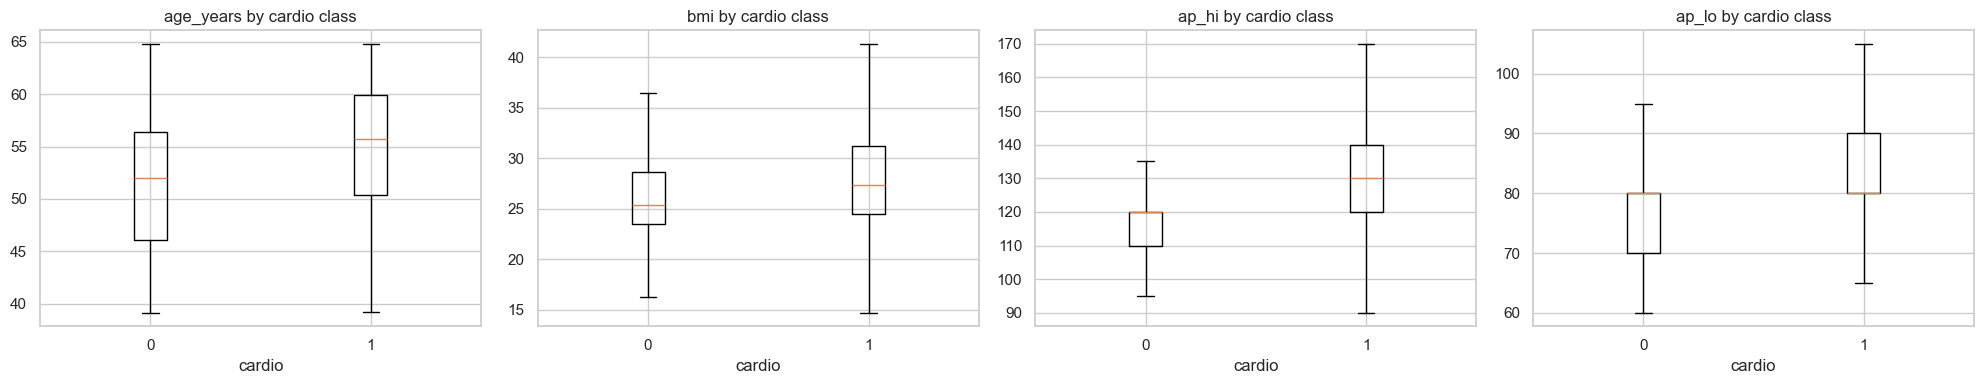

In [6]:
scatter_cols = [c for c in ["age_years", "bmi", "ap_hi", "ap_lo"] if c in X.columns]
if len(scatter_cols) == 0:
    scatter_cols = X.select_dtypes(include=np.number).columns[:4].tolist()

fig, axes = plt.subplots(1, len(scatter_cols), figsize=(5*len(scatter_cols), 4))
axes = np.array(axes).reshape(-1)
classes = sorted(y.unique())

for ax, col in zip(axes, scatter_cols):
    groups = []
    for cls in classes:
        values = X.loc[y == cls, col].dropna()
        if len(values) > 3000:
            values = values.sample(3000, random_state=RANDOM_STATE)
        groups.append(values)
    ax.boxplot(groups, labels=classes, showfliers=False)
    ax.set_title(f"{col} by cardio class")
    ax.set_xlabel("cardio")

plt.tight_layout()
plt.show()

## 5. Stratified train/test split

In [7]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train_raw))
print("Test rows:", len(X_test_raw))
print("Training class distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("Test class distribution:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Training rows: 56000
Test rows: 14000
Training class distribution:


,proportion
cardio,
0,0.500304
1,0.499696


Test class distribution:


,proportion
cardio,
0,0.500286
1,0.499714


## 6. Missing-value handling and outlier boxplots before treatment

Missing values after imputation: 0


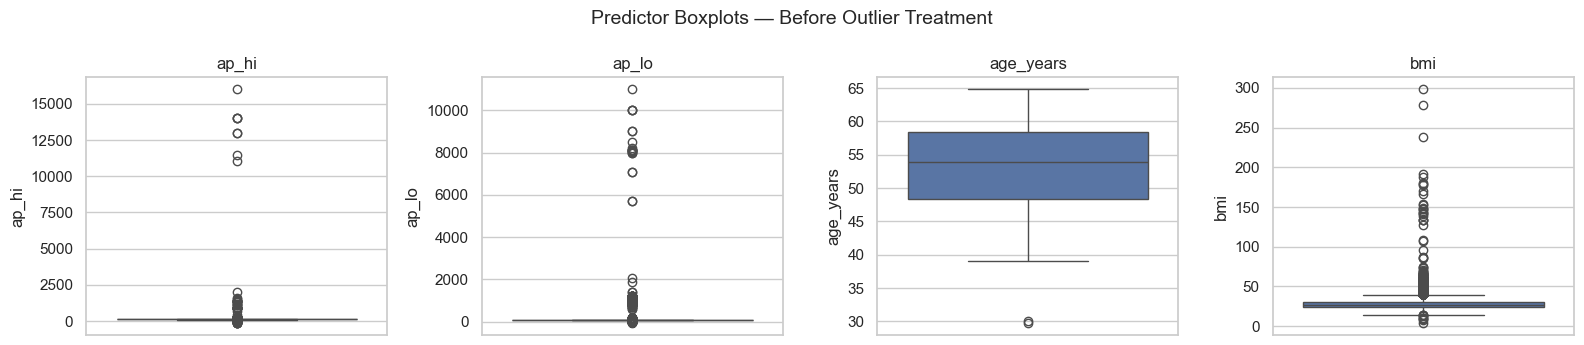

,feature,lower_bound,upper_bound,outlier_count_train
0,ap_hi,90.000000,170.000000,1109
1,ap_lo,65.000000,105.000000,3671
2,age_years,33.380561,73.369610,2
3,bmi,14.354454,39.742883,1623


In [8]:
categorical_cols = [c for c in ["gender", "cholesterol", "gluc", "smoke", "alco", "active"] if c in X_train_raw.columns]
numeric_cols = X_train_raw.select_dtypes(include=np.number).columns.tolist()
continuous_cols = [c for c in numeric_cols if c not in categorical_cols]

imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns, index=X_train_raw.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns, index=X_test_raw.index)

def get_iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

def plot_boxplots(frame, columns, title, max_cols=4):
    if not columns:
        print("No continuous columns available.")
        return
    ncols = min(max_cols, len(columns))
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.5*nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, columns):
        sns.boxplot(y=frame[col], ax=ax)
        ax.set_title(col)
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

print("Missing values after imputation:", int(X_train_imp.isna().sum().sum()))
plot_boxplots(X_train_imp, continuous_cols, "Predictor Boxplots — Before Outlier Treatment")

outlier_rows = []
for col in continuous_cols:
    lo, hi = get_iqr_bounds(X_train_imp[col])
    outlier_rows.append({"feature": col, "lower_bound": lo, "upper_bound": hi,
                         "outlier_count_train": int(((X_train_imp[col] < lo) | (X_train_imp[col] > hi)).sum())})
display(pd.DataFrame(outlier_rows))

## 7. Outlier treatment and boxplots after treatment

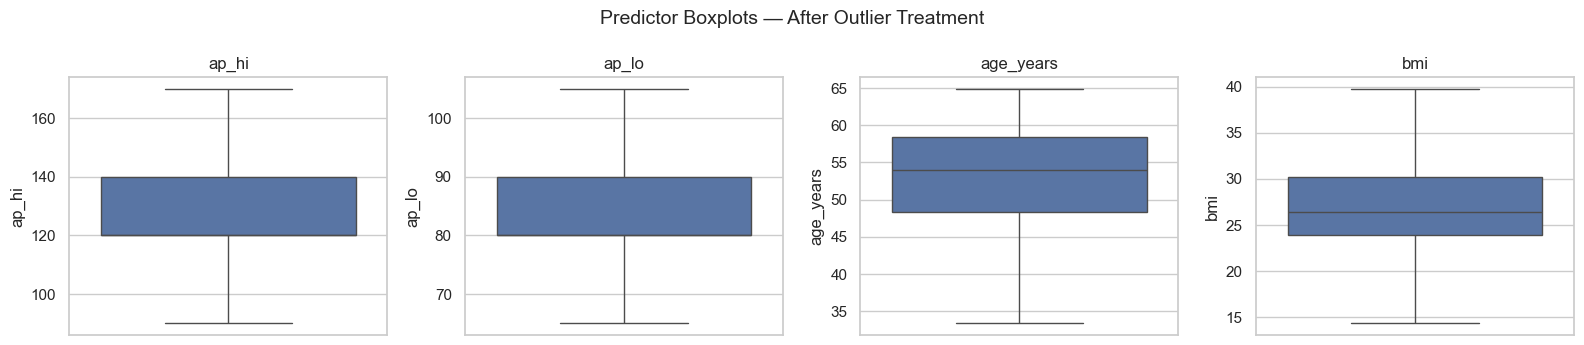

In [9]:
X_train_clean = X_train_imp.copy()
X_test_clean = X_test_imp.copy()

# Do not clip binary/category-coded features; clip continuous measurements using training-set IQR bounds.
for col in continuous_cols:
    lo, hi = get_iqr_bounds(X_train_imp[col])
    X_train_clean[col] = X_train_clean[col].clip(lo, hi)
    X_test_clean[col] = X_test_clean[col].clip(lo, hi)

plot_boxplots(X_train_clean, continuous_cols, "Predictor Boxplots — After Outlier Treatment")

## 8. Scaling — fitted on training data only

In [10]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_clean), columns=X_train_clean.columns, index=X_train_clean.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_clean), columns=X_test_clean.columns, index=X_test_clean.index)
print("Scaled training shape:", X_train_scaled.shape)

Scaled training shape: (56000, 10)


# Algorithm 9 — Bagging Classifier

Bagging trains multiple base estimators on bootstrap samples and aggregates their predictions. A Decision Tree is used as the base estimator. The code supports both newer and older scikit-learn versions.

In [11]:
# Algorithm 9: Bagging Classifier
try:
    bagging_model = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    )
except TypeError:  # Older scikit-learn versions
    bagging_model = BaggingClassifier(
        base_estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    )

bagging_model.fit(X_train_scaled, y_train)
bagging_pred = bagging_model.predict(X_test_scaled)
bagging_proba = bagging_model.predict_proba(X_test_scaled)[:, 1]

bagging_metrics = {
    "Algorithm": "Bagging Classifier",
    "Accuracy": accuracy_score(y_test, bagging_pred),
    "Precision (weighted)": precision_score(y_test, bagging_pred, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test, bagging_pred, average="weighted", zero_division=0),
    "F1 (weighted)": f1_score(y_test, bagging_pred, average="weighted", zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, bagging_proba)
}
display(pd.DataFrame([bagging_metrics]).round(4))

,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC
0,Bagging Classifier,0.7046,0.7048,0.7046,0.7046,0.7628


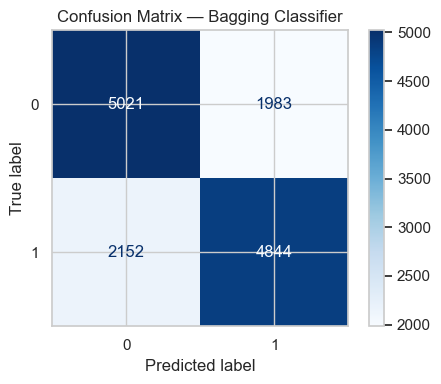

              precision    recall  f1-score   support

           0       0.70      0.72      0.71      7004
           1       0.71      0.69      0.70      6996

    accuracy                           0.70     14000
   macro avg       0.70      0.70      0.70     14000
weighted avg       0.70      0.70      0.70     14000



In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, bagging_pred, ax=ax, cmap="Blues")
ax.set_title("Confusion Matrix — Bagging Classifier")
plt.tight_layout()
plt.show()

print(classification_report(y_test, bagging_pred, zero_division=0))

### Tune Bagging Classifier

In [13]:
# Try a small set of settings so this cell runs faster on a large dataset.
def make_bagging(tree_depth=None, n_estimators=50):
    tree = DecisionTreeClassifier(max_depth=tree_depth, random_state=RANDOM_STATE)
    try:
        return BaggingClassifier(estimator=tree, n_estimators=n_estimators,
                                 random_state=RANDOM_STATE, n_jobs=-1)
    except TypeError:
        return BaggingClassifier(base_estimator=tree, n_estimators=n_estimators,
                                 random_state=RANDOM_STATE, n_jobs=-1)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

sample_n = min(20000, len(X_train_scaled))
X_tune = X_train_scaled.iloc[:sample_n]
y_tune = y_train.iloc[:sample_n]

bagging_model_for_params = make_bagging()
depth_param = "estimator__max_depth" if "estimator" in bagging_model_for_params.get_params() else "base_estimator__max_depth"
bagging_search = GridSearchCV(
    make_bagging(),
    param_grid={"n_estimators": [30, 50], depth_param: [None, 10]},
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1
)
bagging_search.fit(X_tune, y_tune)
bagging_tuned_pred = bagging_search.best_estimator_.predict(X_test_scaled)
bagging_tuned_proba = bagging_search.best_estimator_.predict_proba(X_test_scaled)[:, 1]

display(pd.DataFrame([{
    "Best Parameters": str(bagging_search.best_params_),
    "Best CV Weighted F1": bagging_search.best_score_,
    "Test Accuracy": accuracy_score(y_test, bagging_tuned_pred),
    "Test Precision (weighted)": precision_score(y_test, bagging_tuned_pred, average="weighted", zero_division=0),
    "Test Recall (weighted)": recall_score(y_test, bagging_tuned_pred, average="weighted", zero_division=0),
    "Test F1 (weighted)": f1_score(y_test, bagging_tuned_pred, average="weighted", zero_division=0),
    "Test ROC-AUC": roc_auc_score(y_test, bagging_tuned_proba)
}]).round(4))

,Best Parameters,Best CV Weighted F1,Test Accuracy,Test Precision (weighted),Test Recall (weighted),Test F1 (weighted),Test ROC-AUC
0,"{'estimator__max_depth': 10, 'n_estimators': 50}",0.7337,0.7256,0.7286,0.7256,0.7248,0.7919


# Algorithm 10 — MLP Classifier (Neural Network)

MLP learns nonlinear patterns using hidden layers and activation functions. Scaling is important for neural-network optimisation. The parameter search tunes hidden-layer size and activation function.

In [14]:
# Algorithm 10: MLP Neural Network Classifier
mlp_model = MLPClassifier(hidden_layer_sizes=(50,), max_iter=150,
                          early_stopping=True, random_state=RANDOM_STATE)
mlp_model.fit(X_train_scaled, y_train)
mlp_pred = mlp_model.predict(X_test_scaled)
mlp_proba = mlp_model.predict_proba(X_test_scaled)[:, 1]

mlp_metrics = {
    "Algorithm": "MLP Classifier",
    "Accuracy": accuracy_score(y_test, mlp_pred),
    "Precision (weighted)": precision_score(y_test, mlp_pred, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test, mlp_pred, average="weighted", zero_division=0),
    "F1 (weighted)": f1_score(y_test, mlp_pred, average="weighted", zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, mlp_proba)
}
display(pd.DataFrame([mlp_metrics]).round(4))

,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC
0,MLP Classifier,0.7291,0.7295,0.7291,0.7289,0.7958


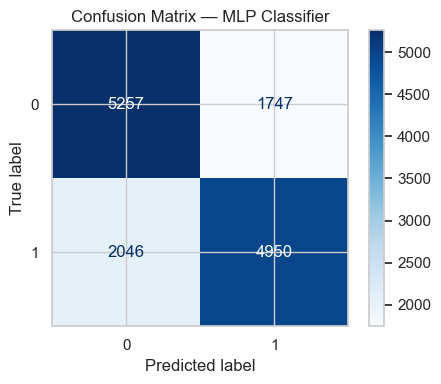

              precision    recall  f1-score   support

           0       0.72      0.75      0.73      7004
           1       0.74      0.71      0.72      6996

    accuracy                           0.73     14000
   macro avg       0.73      0.73      0.73     14000
weighted avg       0.73      0.73      0.73     14000



In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, mlp_pred, ax=ax, cmap="Blues")
ax.set_title("Confusion Matrix — MLP Classifier")
plt.tight_layout()
plt.show()

print(classification_report(y_test, mlp_pred, zero_division=0))

### Tune MLP Classifier

In [16]:
# Tune a small number of neural-network settings for faster execution.
mlp_search = GridSearchCV(
    MLPClassifier(max_iter=120, early_stopping=True, random_state=RANDOM_STATE),
    param_grid={
        "hidden_layer_sizes": [(50,), (100,)],
        "activation": ["relu"]
    },
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1
)

sample_n = min(20000, len(X_train_scaled))
X_tune_scaled = X_train_scaled.iloc[:sample_n]
y_tune = y_train.iloc[:sample_n]
mlp_search.fit(X_tune_scaled, y_tune)
mlp_tuned_pred = mlp_search.best_estimator_.predict(X_test_scaled)
mlp_tuned_proba = mlp_search.best_estimator_.predict_proba(X_test_scaled)[:, 1]

display(pd.DataFrame([{
    "Best Parameters": str(mlp_search.best_params_),
    "Best CV Weighted F1": mlp_search.best_score_,
    "Test Accuracy": accuracy_score(y_test, mlp_tuned_pred),
    "Test Precision (weighted)": precision_score(y_test, mlp_tuned_pred, average="weighted", zero_division=0),
    "Test Recall (weighted)": recall_score(y_test, mlp_tuned_pred, average="weighted", zero_division=0),
    "Test F1 (weighted)": f1_score(y_test, mlp_tuned_pred, average="weighted", zero_division=0),
    "Test ROC-AUC": roc_auc_score(y_test, mlp_tuned_proba)
}]).round(4))

,Best Parameters,Best CV Weighted F1,Test Accuracy,Test Precision (weighted),Test Recall (weighted),Test F1 (weighted),Test ROC-AUC
0,"{'activation': 'relu', 'hidden_layer_sizes': (...",0.7329,0.7288,0.7289,0.7288,0.7287,0.7948


## 9. ROC curves — baseline models

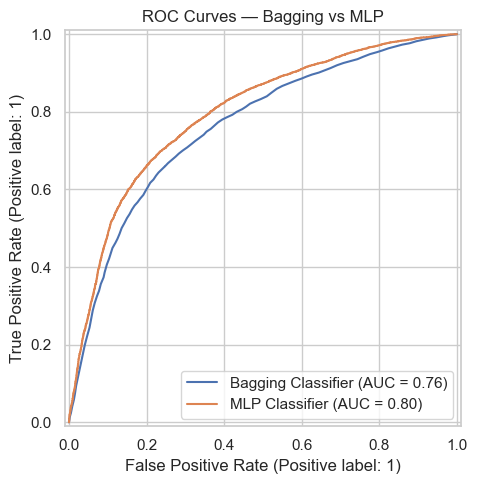

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, bagging_proba, name="Bagging Classifier", ax=ax)
RocCurveDisplay.from_predictions(y_test, mlp_proba, name="MLP Classifier", ax=ax)
ax.set_title("ROC Curves — Bagging vs MLP")
plt.tight_layout()
plt.show()

## 10. Consolidated comparison table

In [18]:
comparison = pd.DataFrame([
    bagging_metrics,
    mlp_metrics
]).sort_values("F1 (weighted)", ascending=False).reset_index(drop=True)
display(comparison.round(4))

,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC
0,MLP Classifier,0.7291,0.7295,0.7291,0.7289,0.7958
1,Bagging Classifier,0.7046,0.7048,0.7046,0.7046,0.7628


## 11. Review 2 conclusion prompts

Use your actual notebook outputs to answer:
1. Which model has higher weighted F1 and ROC-AUC?
2. How do the confusion matrices compare?
3. Did hyperparameter tuning improve weighted F1?
4. Why is scaling important for MLP?
5. Why is `cardio` excluded from predictors?
6. What is the difference between Bagging and MLP?

**Method note:** Imputation, outlier bounds, and scaling are learned from the training set only. The held-out test set is reserved for evaluation.